In [ ]:
%pip install qiskit qiskit-aer matplotlib
%pip install pylatexenc

In [ ]:
# Tools for building and running a quantum circuit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator

# Tools for showing the measurement results
from qiskit.visualization import plot_histogram
import numpy as np
import matplotlib.pyplot as plt

print("Imports completed successfully!")

Imports completed successfully!


In [ ]:
# XOR gives 1 when the two input bits are different
def XOR(qc, a, b, output):
    qc.cx(a, output)
    qc.cx(b, output)

print("XOR function defined.")

XOR function defined.


In [ ]:
# Qubit indices: a=0, b=1, c=2, d=3

# Each pair must have different values:
# a != b, a != c, b != d, c != d
clause_list = [
    [0, 1],
    [0, 2],
    [1, 3],
    [2, 3]
]

print("Number of cells:", 4)
print("Number of constraints:", len(clause_list))
print("Possible grids:", 2**4)

Number of cells: 4
Number of constraints: 4
Possible grids: 16


In [ ]:
# The Oracle marks a grid if all four rules are satisfied
def sudoku_oracle(qc, clause_list, clause_qubits, output_qubit):

    # Check each pair and store its result
    for i, clause in enumerate(clause_list):
        XOR(qc, clause[0], clause[1], clause_qubits[i])

    # Flip the output only when all four checks are 1
    qc.mcx(list(clause_qubits), output_qubit)

    # Undo the checks to reset the temporary qubits
    for i, clause in enumerate(clause_list):
        XOR(qc, clause[0], clause[1], clause_qubits[i])

print("Sudoku Oracle defined.")

Sudoku Oracle defined.


In [ ]:
# The diffuser amplifies the marked answers
def diffuser(nqubits):
    qc = QuantumCircuit(nqubits)

    # Change from the equal-superposition basis
    for qubit in range(nqubits):
        qc.h(qubit)

    # Flip the qubits
    for qubit in range(nqubits):
        qc.x(qubit)

    # Apply a multi-controlled operation
    qc.h(nqubits - 1)
    qc.mcx(list(range(nqubits - 1)), nqubits - 1)
    qc.h(nqubits - 1)

    # Reverse the transformations
    for qubit in range(nqubits):
        qc.x(qubit)

    for qubit in range(nqubits):
        qc.h(qubit)

    return qc.to_gate(label="Diffuser")

print("Diffuser defined.")

Diffuser defined.


Quantum circuit initialized.


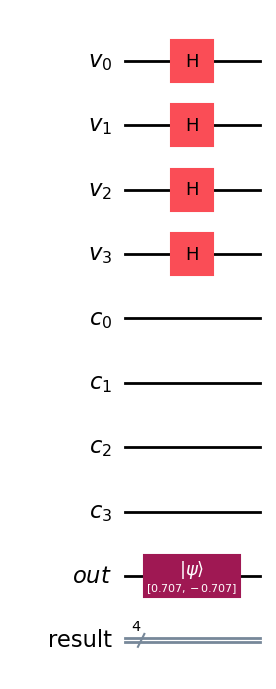

In [ ]:
# Create the registers
var_qubits = QuantumRegister(4, name="v")
clause_qubits = QuantumRegister(4, name="c")
output_qubit = QuantumRegister(1, name="out")
cbits = ClassicalRegister(4, name="result")

qc = QuantumCircuit(
    var_qubits, clause_qubits, output_qubit, cbits
)

# Prepare the output qubit in the |-> state
qc.initialize([1, -1] / np.sqrt(2), output_qubit)

# Put the four Sudoku cells into superposition
qc.h(var_qubits)

print("Quantum circuit initialized.")
qc.draw("mpl")

Two Grover iterations added.


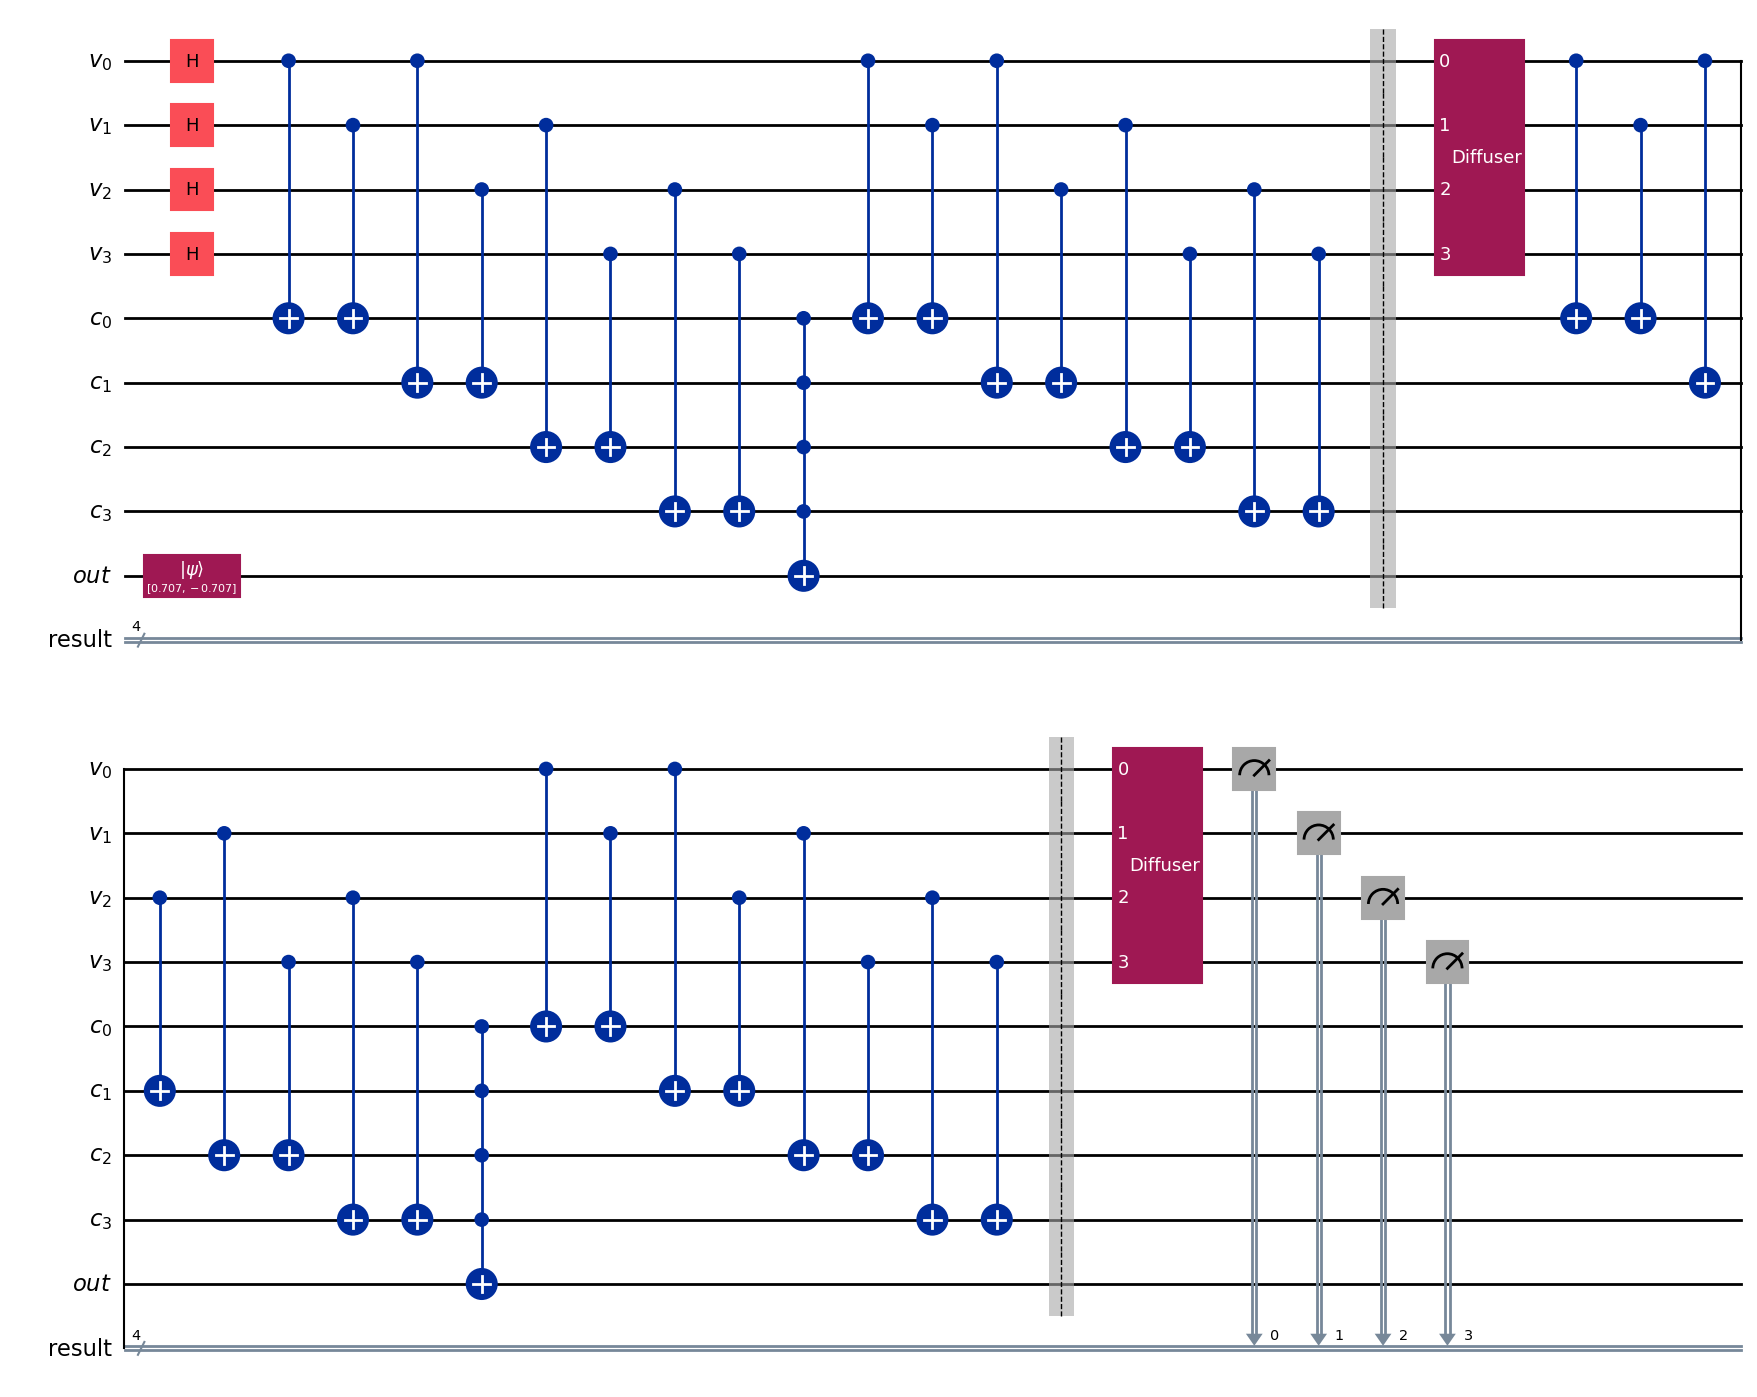

In [ ]:
# First iteration
sudoku_oracle(
    qc, clause_list, clause_qubits, output_qubit[0]
)
qc.barrier()

qc.append(diffuser(4), list(var_qubits))

# Second iteration
sudoku_oracle(
    qc, clause_list, clause_qubits, output_qubit[0]
)
qc.barrier()

qc.append(diffuser(4), list(var_qubits))

# Measure the four Sudoku cells
qc.measure(var_qubits, cbits)

print("Two Grover iterations added.")
qc.draw("mpl")

In [ ]:
# Simulate the circuit 1024 times
simulator = AerSimulator()

compiled_qc = transpile(qc, simulator)
result = simulator.run(compiled_qc, shots=1024).result()

counts = result.get_counts()

print("Measurement results:")
for state, count in sorted(counts.items()):
    print(f"{state}: {count}")

Measurement results:
0000: 3
0001: 7
0010: 4
0011: 4
0100: 5
0101: 6
0110: 478
0111: 7
1000: 2
1001: 479
1010: 8
1011: 5
1100: 2
1101: 6
1110: 4
1111: 4


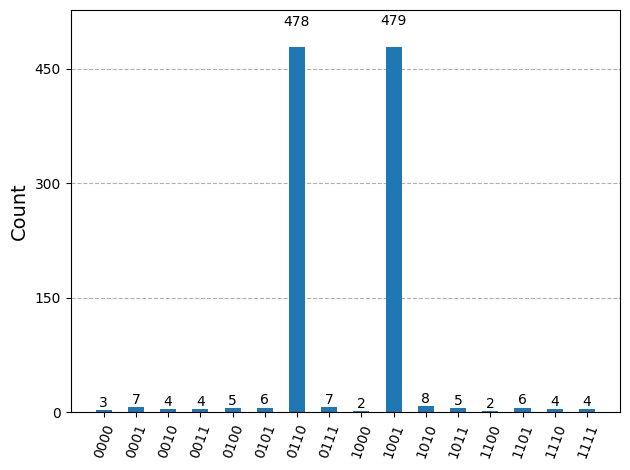

In [ ]:
fig = plot_histogram(counts)
display(fig)